# 03. ML comparison, calibration and error analysis

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd()
if not (ROOT / "src").exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.config import RESULTS_DIR, ALL_MODEL_FEATURES, FORBIDDEN_COLUMNS
from src.data import load_raw_dataset, clean_and_prepare_dataset, attach_label_availability
from src.features import compute_schedule_and_calendar_features
summary = json.loads((RESULTS_DIR / "run_summary.json").read_text())
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 11})


Logistic Regression and XGBoost are the required Phase 1 models. The embedding MLP is supplementary. AP is Average Precision, not trapezoidal PR area. Every operating threshold uses the same selected probability scale at selection and inference.

In [2]:
display(pd.read_csv(RESULTS_DIR / "metrics/model_comparison.csv"))
metrics = json.loads((RESULTS_DIR / "metrics/evaluation_metrics.json").read_text())
display(pd.DataFrame([{ "model": m["model_name"], "train_AP": m.get("training_average_precision"), "test_raw_AP": m["pr_auc"], "test_calibrated_AP": m.get("average_precision_calibrated"), "alerts": m["operational_alert_count"], "precision_defined": m["precision_defined"]} for m in metrics]))

,Model,PR-AUC (Avg Prec),ROC-AUC,Brier Score (Raw),Brier Score (Calibrated),Operational Threshold,Precision @ Op Threshold,Recall @ Op Threshold,F1 @ Op Threshold,F1 @ 0.50 Threshold,Test Prevalence
0,Logistic Regression,0.3200,0.5797,0.2396,0.2396,0.091,0.3399,0.1967,0.2492,0.0000,0.2686
1,XGBoost,0.3722,0.6367,0.1910,0.1910,0.206,0.3449,0.6774,0.4571,0.0000,0.2686
2,PyTorch Embedding MLP,0.3936,0.6506,0.2017,0.2017,0.063,0.3195,0.8304,0.4614,0.0115,0.2686
3,Constant training prior,0.2686,0.5000,0.1965,0.1965,0.500,0.0000,0.0000,0.0000,0.0000,0.2686


,model,train_AP,test_raw_AP,test_calibrated_AP,alerts,precision_defined
0,Logistic Regression,0.424738,0.320034,0.320034,7550,True
1,XGBoost,0.433813,0.372242,0.372242,25622,True
2,PyTorch Embedding MLP,0.492752,0.393624,0.393624,33913,True
3,Constant training prior,NaN,0.268562,0.268562,0,False


In [3]:
search = json.loads((RESULTS_DIR / "reports/temporal_search.json").read_text())
display(pd.DataFrame(search["candidate_summary"]))
display(pd.DataFrame(search["selected_hyperparameters"]).T)

,model,feature_set,parameters,mean_average_precision,std_average_precision,mean_brier_score,median_best_rounds
0,logistic_regression,schedule_demand,"{'lr_c': 0.03, 'lr_class_weight': None}",0.394011,0.101155,0.183653,NaN
1,logistic_regression,schedule_demand,"{'lr_c': 0.03, 'lr_class_weight': 'balanced'}",0.392644,0.100622,0.257087,NaN
2,logistic_regression,schedule_demand,"{'lr_c': 0.3, 'lr_class_weight': None}",0.393158,0.100450,0.184542,NaN
3,logistic_regression,schedule_demand,"{'lr_c': 0.3, 'lr_class_weight': 'balanced'}",0.391422,0.099695,0.254235,NaN
4,logistic_regression,cyclic_schedule_demand,"{'lr_c': 0.03, 'lr_class_weight': None}",0.399857,0.101402,0.180093,NaN
5,logistic_regression,cyclic_schedule_demand,"{'lr_c': 0.03, 'lr_class_weight': 'balanced'}",0.399342,0.101655,0.245416,NaN
6,logistic_regression,cyclic_schedule_demand,"{'lr_c': 0.3, 'lr_class_weight': None}",0.398937,0.101394,0.180206,NaN
7,logistic_regression,cyclic_schedule_demand,"{'lr_c': 0.3, 'lr_class_weight': 'balanced'}",0.398340,0.101486,0.245458,NaN
8,logistic_regression,history_rates_demand,"{'lr_c': 0.03, 'lr_class_weight': None}",0.402082,0.100862,0.185893,NaN
9,logistic_regression,history_rates_demand,"{'lr_c': 0.03, 'lr_class_weight': 'balanced'}",0.400765,0.100482,0.257933,NaN


,lr_c,lr_max_iter,lr_solver,lr_class_weight,xgb_n_estimators,xgb_max_depth,xgb_learning_rate,xgb_subsample,xgb_colsample_bytree,xgb_tree_method,...,mlp_carrier_emb_dim,mlp_origin_emb_dim,mlp_dest_emb_dim,mlp_hidden_dims,mlp_dropout,mlp_learning_rate,mlp_weight_decay,mlp_batch_size,mlp_epochs,mlp_early_stopping_patience
logistic_regression,0.03,1000,lbfgs,None,150,5,0.08,1.0,1.0,hist,...,16,16,32,"[128, 64, 32]",0.2,0.001,0.0001,512,20,5
xgboost,0.1,1000,lbfgs,balanced,42,3,0.06,1.0,1.0,hist,...,16,16,32,"[128, 64, 32]",0.2,0.001,0.0001,512,20,5


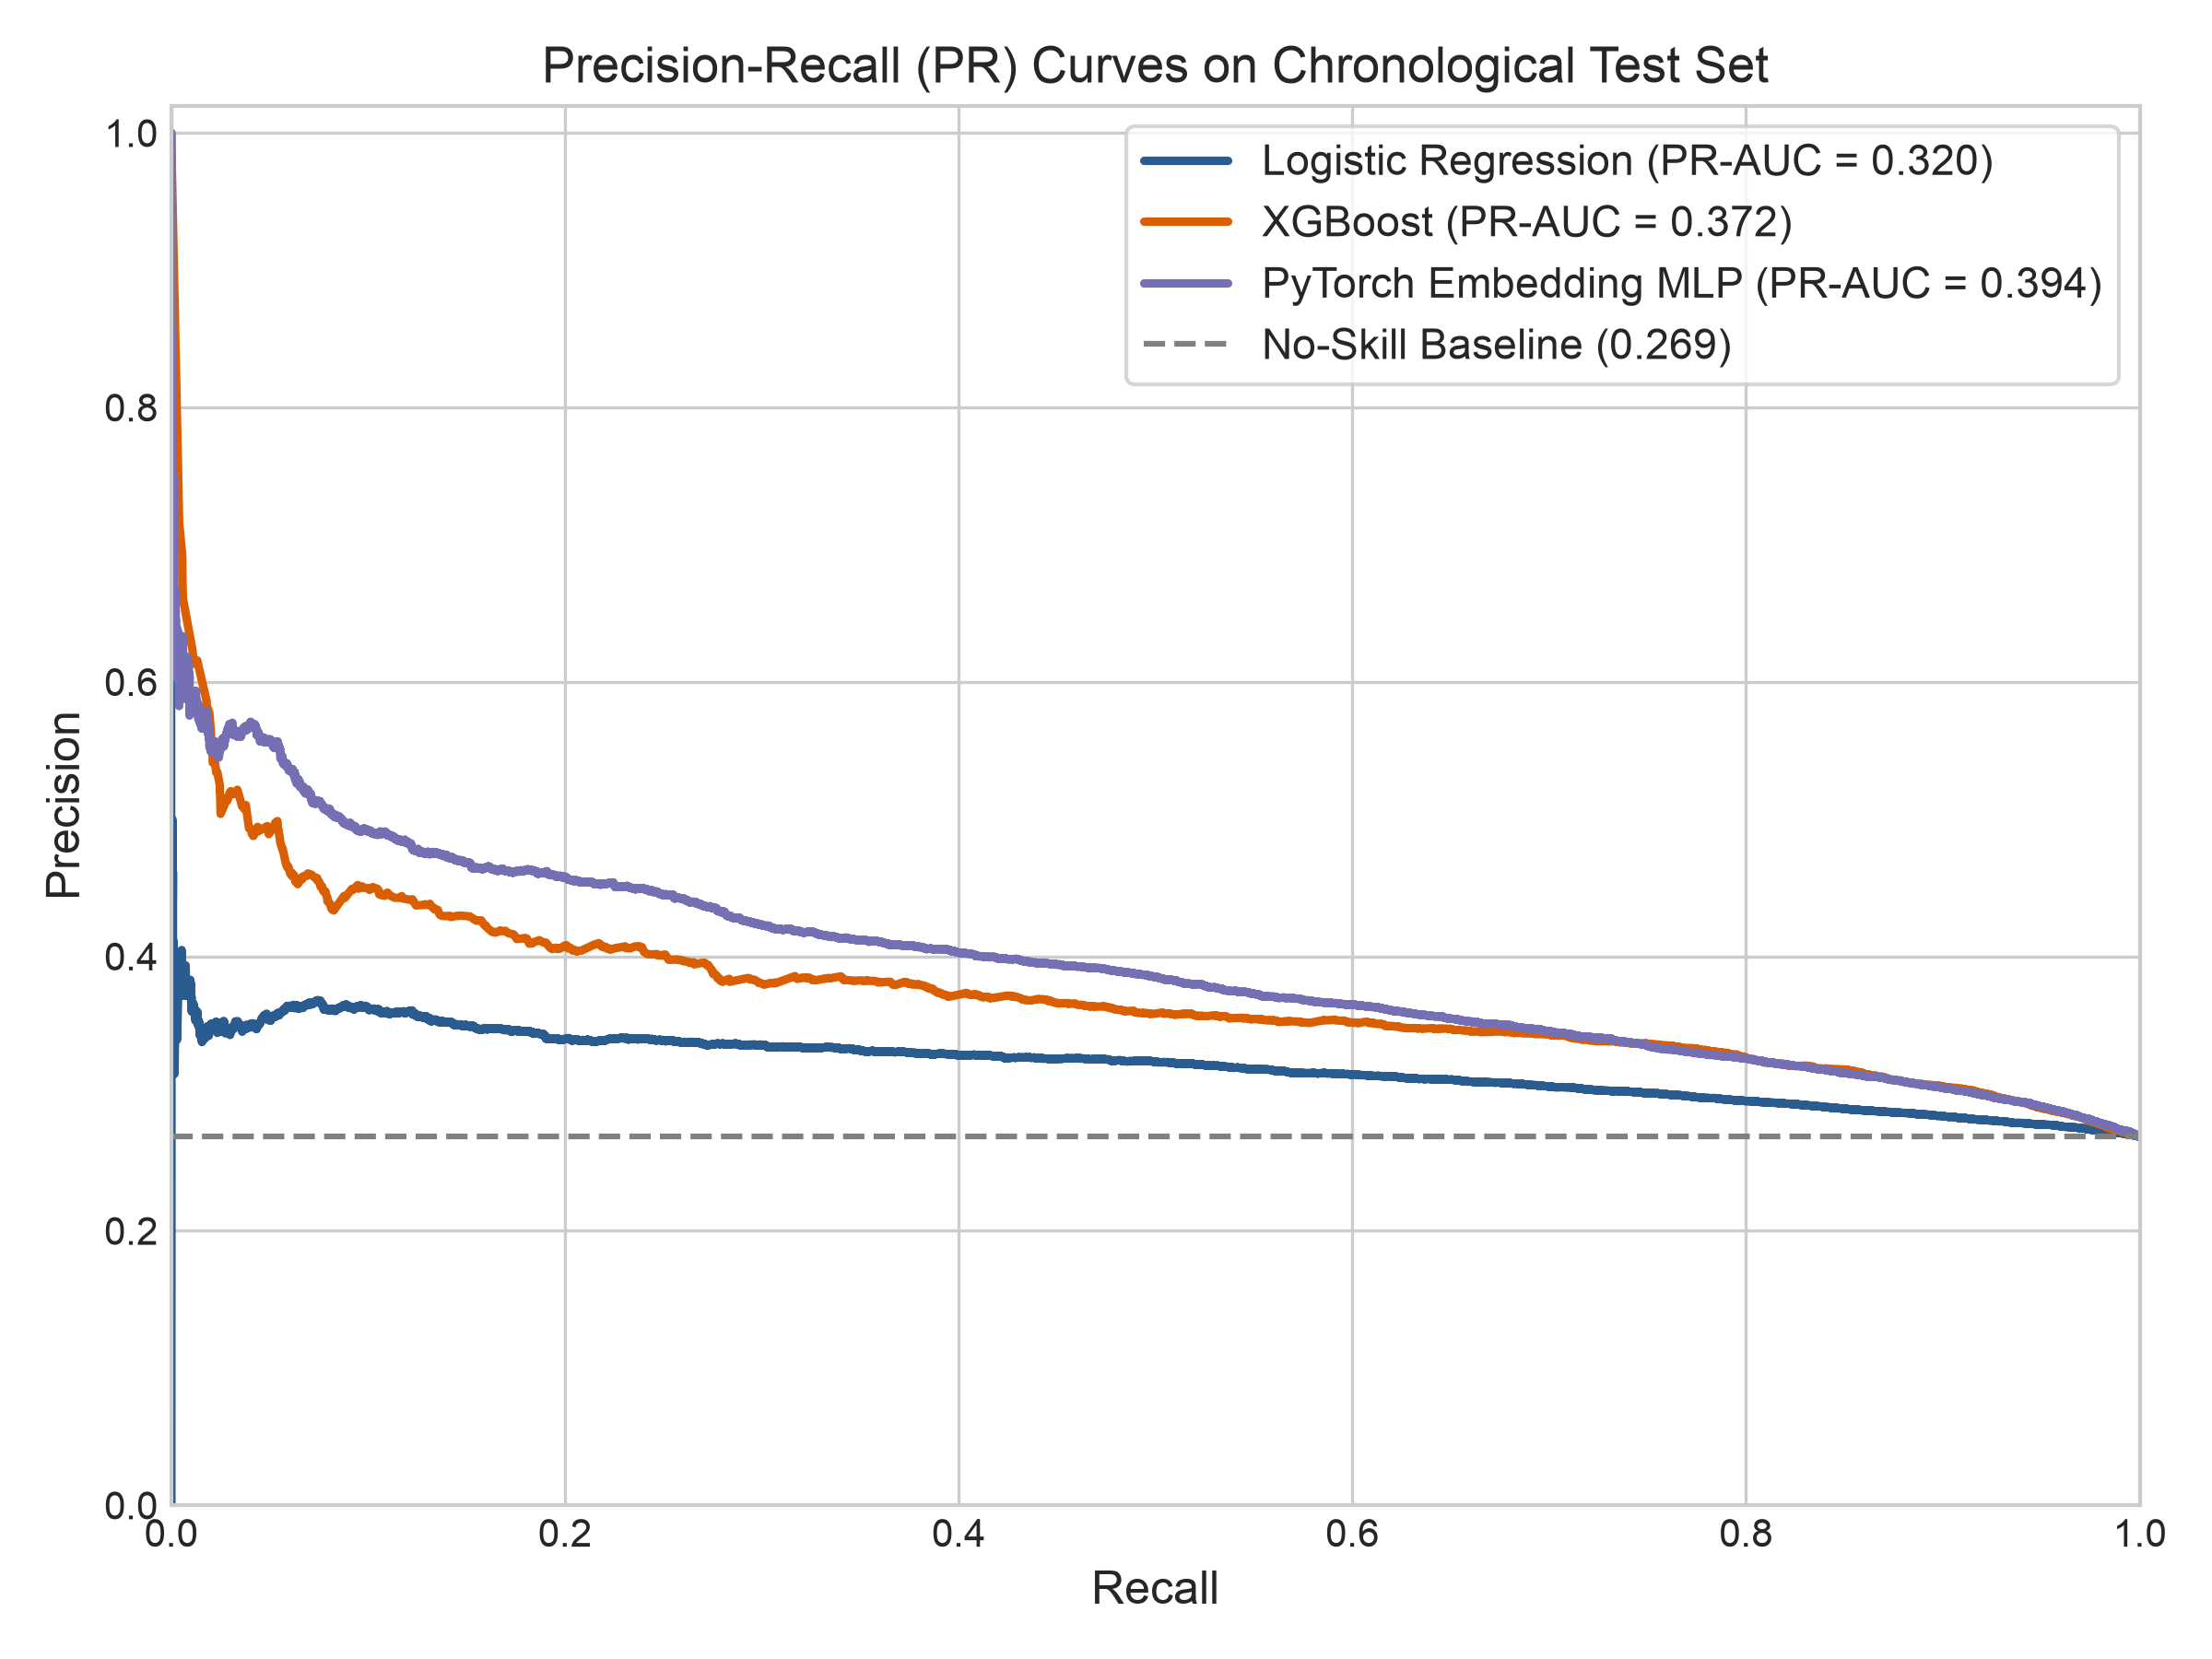

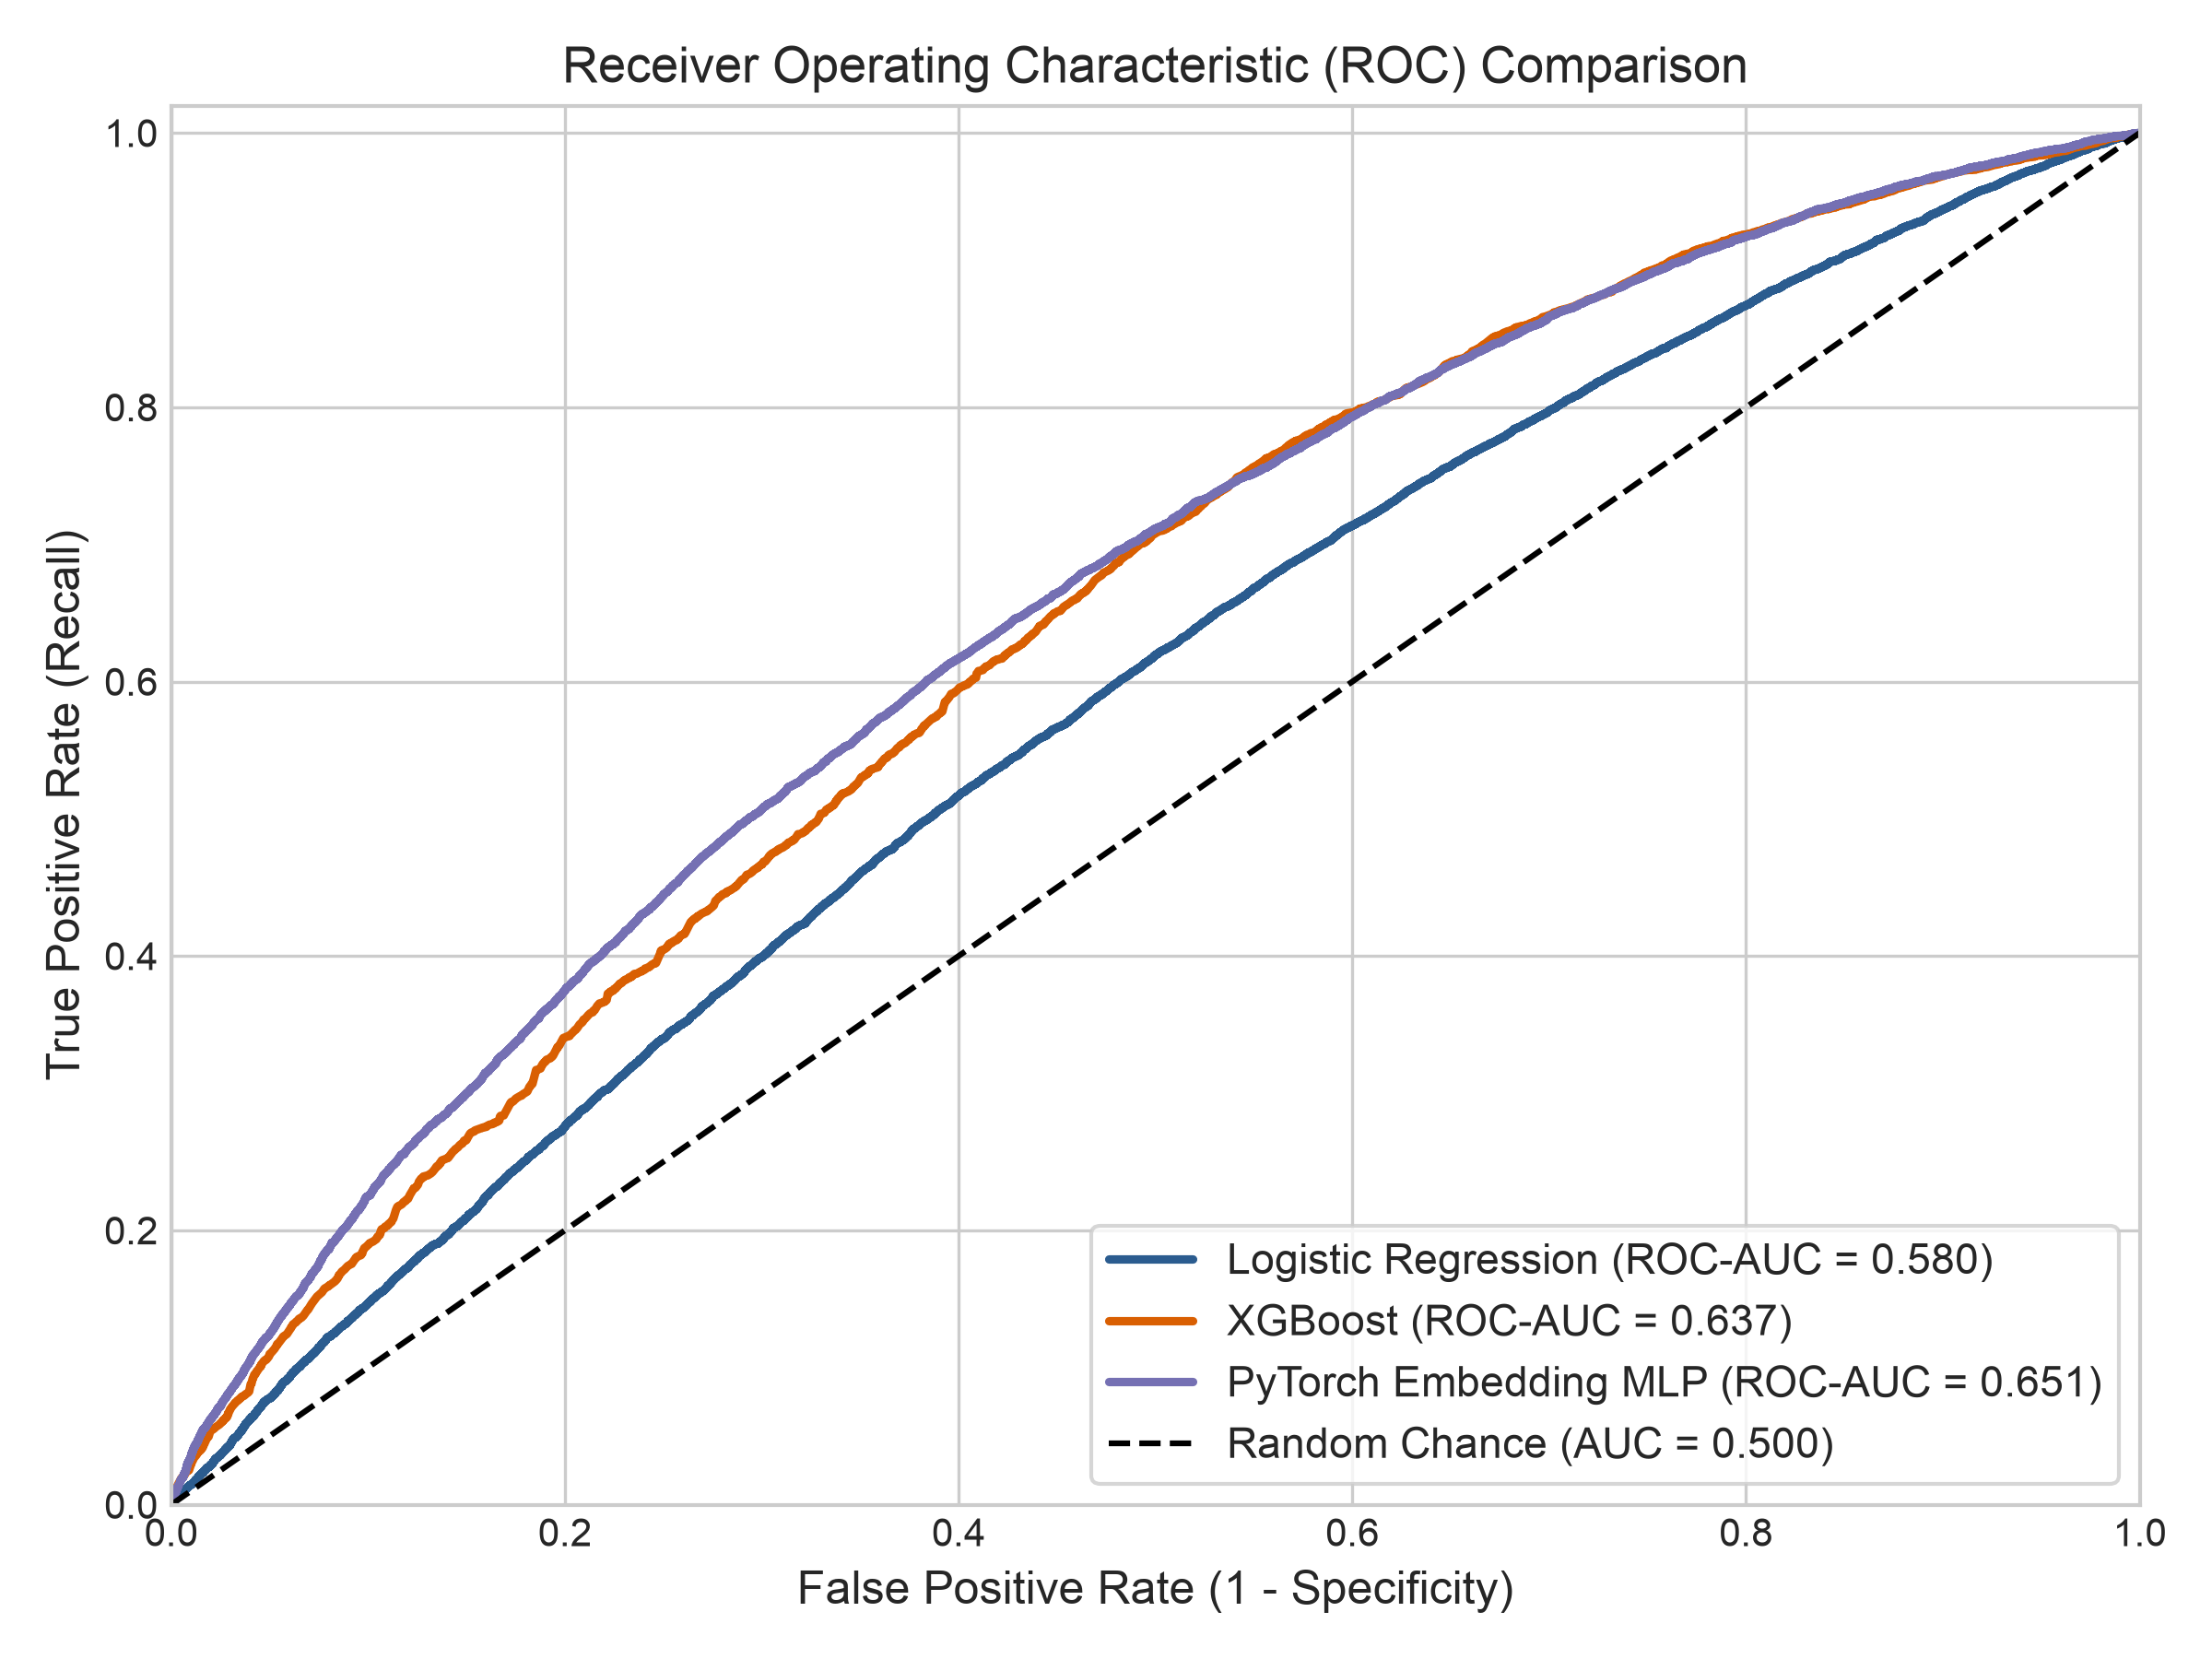

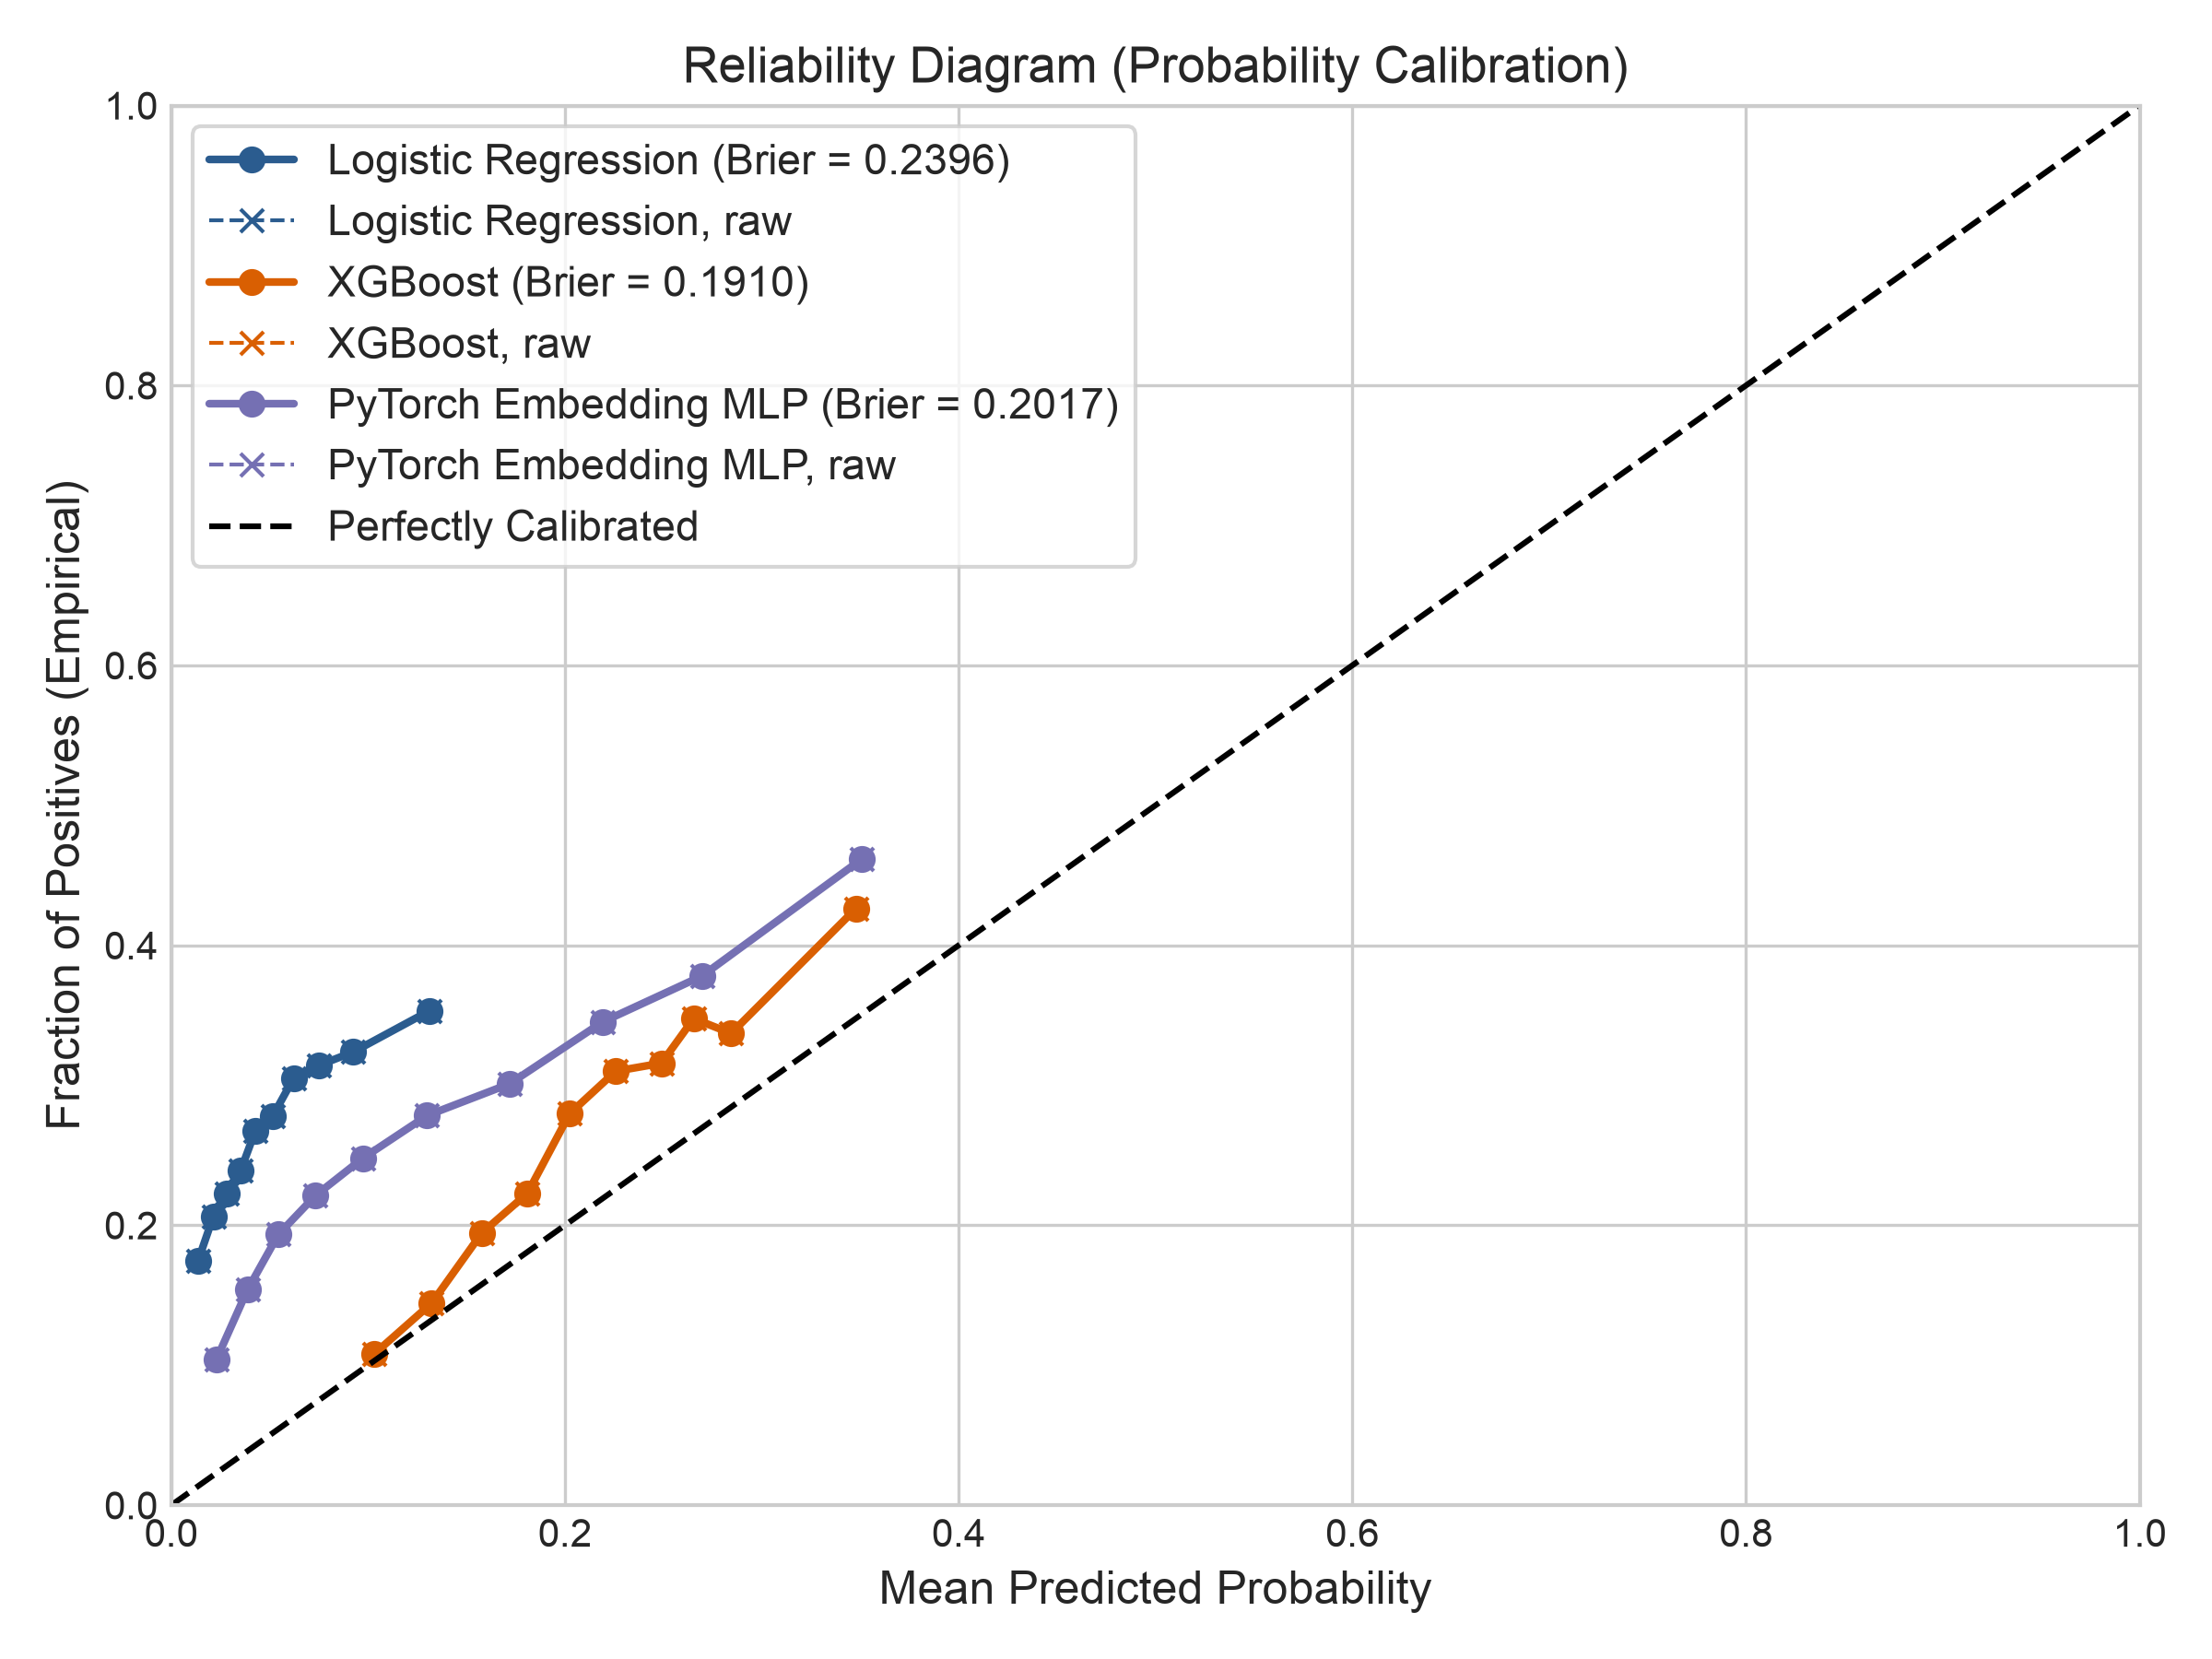

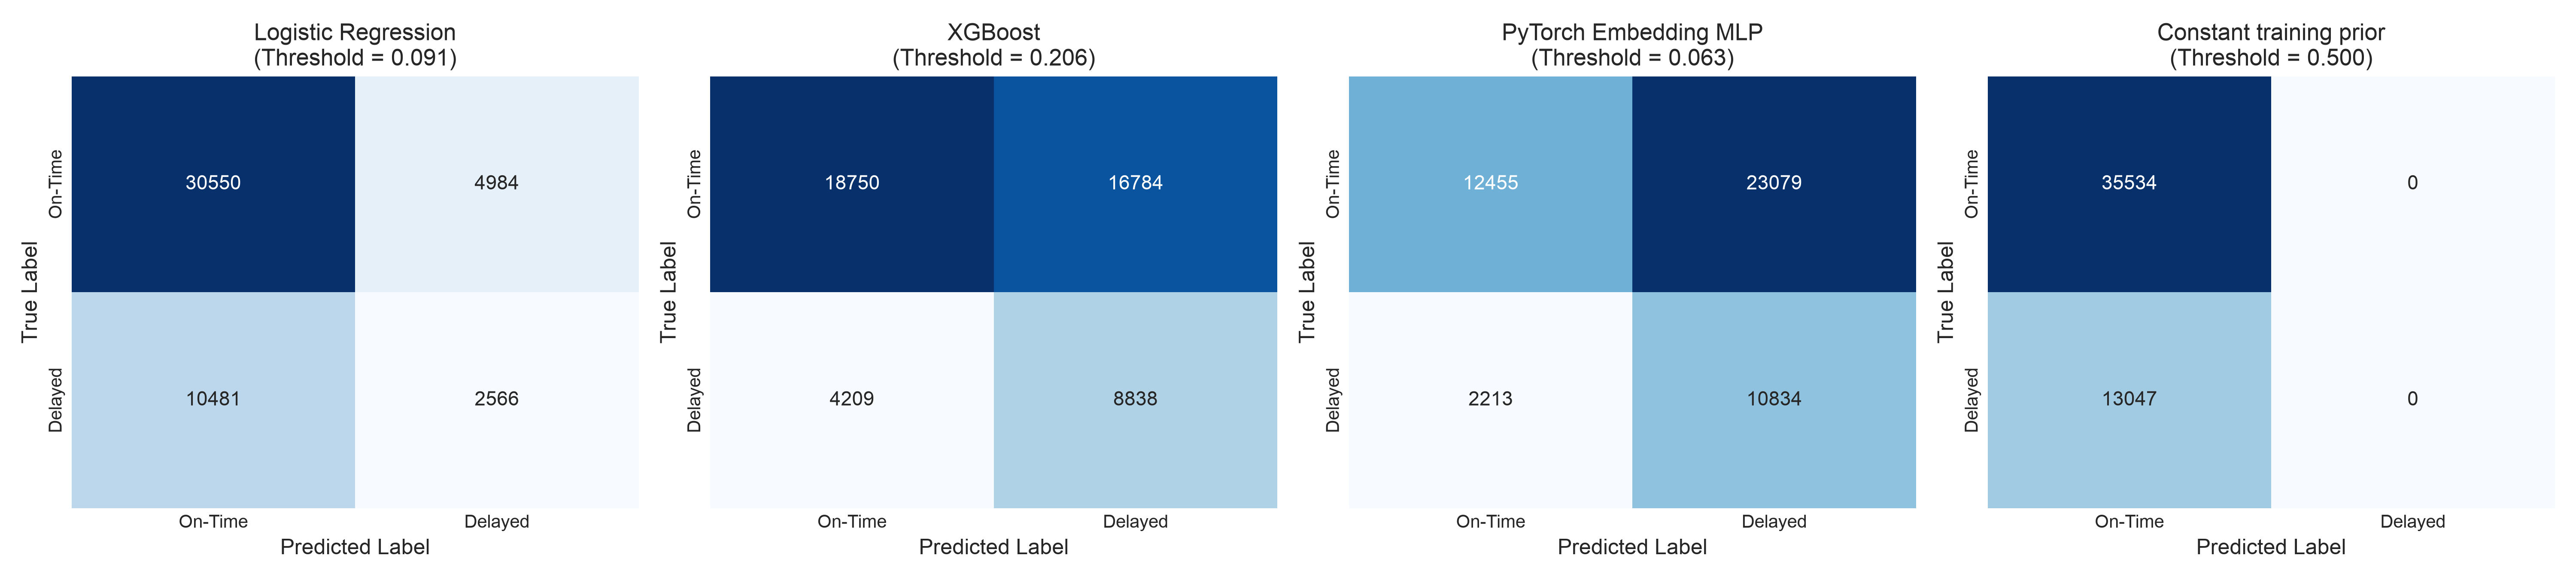

In [4]:
from IPython.display import display, Image
for name in ["pr_curves.png", "roc_curves.png", "calibration_curves.png", "confusion_matrices.png"]:
    display(Image(filename=str(RESULTS_DIR / "figures" / name), width=900))

Calibration is a development-data choice, including the identity option. A lower test Brier score is desirable but is not used to choose the calibrator. Raw and selected reliability curves accompany Brier loss because the loss also reflects discrimination.

In [5]:
calibration = json.loads((RESULTS_DIR / "reports/calibration_selection.json").read_text())
for model, result in calibration.items():
    print(model, "selected:", result["selected_method"])
    display(pd.DataFrame(result["candidates"]))
for metric in metrics:
    if "threshold_selection_metadata" in metric:
        print(metric["model_name"])
        display(pd.Series(metric["threshold_selection_metadata"]).to_frame("value"))

logistic_regression selected: none


,method,selection_brier_score
0,none,0.147932
1,sigmoid,0.155948
2,isotonic,0.156045


xgboost selected: none


,method,selection_brier_score
0,none,0.142682
1,sigmoid,0.150347
2,isotonic,0.150221


pytorch_mlp selected: none


...

,value
target_precision,0.7
selected_threshold,0.090632
validation_precision_at_threshold,0.23109
validation_recall_at_threshold,0.632586
validation_f1_at_threshold,0.338516
target_precision_met,False
selection_dataset,threshold_validation
probability_scale,selected_calibrator_output
selection_rule,max_recall_at_target_precision_else_max_f1_wit...
minimum_alerts,100


XGBoost


,value
target_precision,0.7
selected_threshold,0.206462
validation_precision_at_threshold,0.235137
validation_recall_at_threshold,0.583303
validation_f1_at_threshold,0.335165
target_precision_met,False
selection_dataset,threshold_validation
probability_scale,selected_calibrator_output
selection_rule,max_recall_at_target_precision_else_max_f1_wit...
minimum_alerts,100


PyTorch Embedding MLP


,value
target_precision,0.7
selected_threshold,0.063429
validation_precision_at_threshold,0.209159
validation_recall_at_threshold,0.722324
validation_f1_at_threshold,0.324387
target_precision_met,False
selection_dataset,threshold_validation
probability_scale,selected_calibrator_output
selection_rule,max_recall_at_target_precision_else_max_f1_wit...
minimum_alerts,100


,model,features,numeric_feature_count,evaluation_partition,average_precision,roc_auc,brier_score
0,logistic_regression,schedule_calendar,19,calibration_selection,0.338770,0.689450,0.149472
1,xgboost,schedule_calendar,19,calibration_selection,0.328632,0.671152,0.144121
2,logistic_regression,plus_history,30,calibration_selection,0.334873,0.690070,0.148445
3,xgboost,plus_history,30,calibration_selection,0.289475,0.665016,0.144984
4,logistic_regression,plus_scheduled_demand,32,calibration_selection,0.339215,0.694774,0.147931
5,xgboost,plus_scheduled_demand,32,calibration_selection,0.286636,0.664829,0.144920
6,logistic_regression,frozen_history_reference,32,calibration_selection,0.334847,0.691309,0.145522
7,xgboost,frozen_history_reference,32,calibration_selection,0.307407,0.673004,0.144068


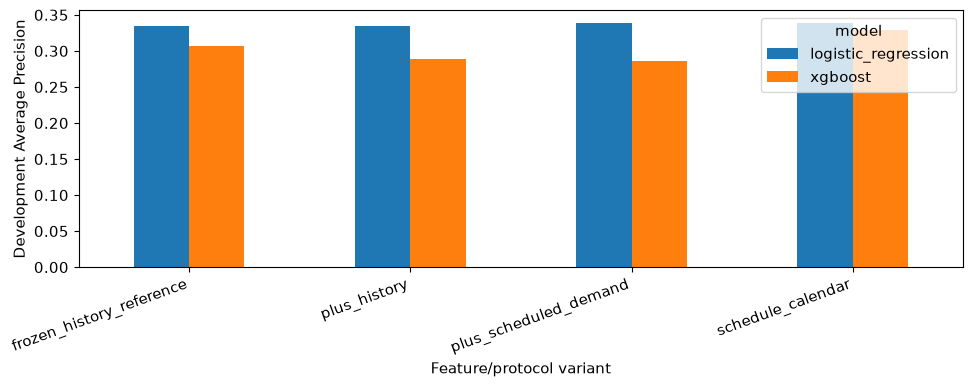

In [6]:
ablation = pd.read_csv(RESULTS_DIR / "metrics/feature_ablation.csv")
display(ablation)
ax = ablation.pivot(index="features", columns="model", values="average_precision").plot.bar(figsize=(10, 4))
ax.set(ylabel="Development Average Precision", xlabel="Feature/protocol variant")
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()

The frozen-history reference keeps the same fitted model configuration but uses training-only events frozen at the first selection-block decision time. Its recent-history window may contain no training events. The primary daily replay updates only released historical outcomes. Estimator weights remain fixed. The ablation is evaluated on development data, not used to optimize the test result.

In [7]:
slices = pd.read_csv(RESULTS_DIR / "metrics/error_slices.csv")
display(slices[(slices.model == "xgboost") & (slices.group == "origin")])
display(slices[(slices.model == "xgboost") & (slices.group == "flight_date")].sort_values("brier_score", ascending=False).head(10))
for metric in metrics:
    if "confidence_intervals_95_day_block" in metric:
        print(metric["model_name"], metric["confidence_intervals_95_day_block"])
cohort = pd.read_csv(RESULTS_DIR / "reports/rescheduling_cohort.csv")
display(cohort.describe())

,model,group,value,n,prevalence,average_precision,brier_score,alert_count
93,xgboost,origin,EWR,17099,0.287327,0.420222,0.196993,9193
94,xgboost,origin,JFK,15866,0.256271,0.320130,0.187915,8727
95,xgboost,origin,LGA,15616,0.260502,0.349124,0.187506,7702


,model,group,value,n,prevalence,average_precision,brier_score,alert_count
171,xgboost,flight_date,2013-12-17 00:00:00,835,0.776048,0.883340,0.452939,536
164,xgboost,flight_date,2013-12-10 00:00:00,739,0.698241,0.729735,0.424655,465
168,xgboost,flight_date,2013-12-14 00:00:00,561,0.639929,0.871928,0.424481,161
163,xgboost,flight_date,2013-12-09 00:00:00,900,0.617778,0.778514,0.370058,593
162,xgboost,flight_date,2013-12-08 00:00:00,805,0.547826,0.823558,0.339900,381
159,xgboost,flight_date,2013-12-05 00:00:00,809,0.546354,0.710135,0.317136,526
177,xgboost,flight_date,2013-12-23 00:00:00,960,0.504167,0.746058,0.301481,647
151,xgboost,flight_date,2013-11-27 00:00:00,977,0.437052,0.581951,0.289893,464
176,xgboost,flight_date,2013-12-22 00:00:00,886,0.452596,0.712520,0.285794,435
160,xgboost,flight_date,2013-12-06 00:00:00,904,0.433628,0.599254,0.265766,607


Logistic Regression {'average_precision': {'lower': 0.2713329242760993, 'upper': 0.38291470665761324}, 'roc_auc': {'lower': 0.5489925294085584, 'upper': 0.6125363943419274}, 'brier_score': {'lower': 0.20250302627682687, 'upper': 0.2814956381917}}
XGBoost {'average_precision': {'lower': 0.318822303200801, 'upper': 0.4366761521436712}, 'roc_auc': {'lower': 0.6089205892935201, 'upper': 0.6600482971862311}, 'brier_score': {'lower': 0.169205579534173, 'upper': 0.21395647302269938}}
PyTorch Embedding MLP {'average_precision': {'lower': 0.32948350231519563, 'upper': 0.4638565225594693}, 'roc_auc': {'lower': 0.6167109697404928, 'upper': 0.6820623339036335}, 'brier_score': {'lower': 0.17567334212362767, 'upper': 0.22948978506028656}}


,record_id,baseline_probability,shift_minutes,selected_probability,risk_difference
count,100.000000,100.000000,100.000000,100.000000,100.000000
mean,87239.090000,0.222897,-29.100000,0.211697,-0.011201
std,13286.466273,0.071311,32.038329,0.072313,0.018916
min,61392.000000,0.094281,-60.000000,0.094281,-0.161702
25%,76709.250000,0.167425,-60.000000,0.159607,-0.016877
50%,88544.000000,0.212927,-30.000000,0.201673,-0.005652
75%,97128.750000,0.269320,0.000000,0.262148,0.000000
max,111258.000000,0.407641,60.000000,0.407641,0.000000


Confidence intervals resample whole dates to retain within-day dependence. They describe this test period, not future regions or years. Rescheduling differences are model sensitivities only: no real-world delay reduction is established. See docs/METHODS.md for the prediction contract and limitations.